## NB4 — Modeling & Evaluation

**Objectives**
1. Compare Method 1 (naive split) vs Method 2 (GroupKFold) — leakage check
2. Method 3: within-person paired baseline — does personal calibration help?
3. ~~Track C: Behavioral~~ → **ไม่มีข้อมูลพฤติกรรมใน ds005385** (future work)

**Validation:** GroupKFold by subject (no leakage)

In [1]:
# ===== CELL 1: Imports + Load =====
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('features_final.csv')
df['task_encoded'] = (df['task'] == 'EyesOpen').astype(int)

print(f"Shape: {df.shape}")
print(f"Label distribution:\n{df['label'].value_counts()}")
print(f"Subjects: {df['subject'].nunique()}")

Shape: (2432, 16)
Label distribution:
label
0    1216
1    1216
Name: count, dtype: int64
Subjects: 608


In [2]:
# ===== CELL 2: Feature sets =====
eeg_feats = ['delta', 'theta', 'low_alpha', 'high_alpha', 'alpha',
             'beta', 'slow_fast_ratio', 'theta_beta_ratio', 'task_encoded']

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['age_group_encoded'] = le.fit_transform(df['age_group'])

features_A = eeg_feats
features_B = eeg_feats + ['age_group_encoded']

# Track C: EEG + synthetic behavioral (reaction time proxy from age + task)
np.random.seed(42)

print("Feature sets:")
print(f"  A (EEG only):          {len(features_A)} features")
print(f"  B (EEG + age):         {len(features_B)} features")

Feature sets:
  A (EEG only):          9 features
  B (EEG + age):         10 features


In [3]:
# ===== CELL 3: แบบที่ 1 — train_test_split (เวอร์ชันเดิม, subject leak) =====
print("=" * 60)
print("METHOD 1: train_test_split (naive — subject may leak)")
print("=" * 60)

models = {
    'LogReg': Pipeline([('scaler', StandardScaler()),
                        ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, random_state=42,
                                  eval_metric='logloss', verbosity=0),
}

results_split = []
for feat_name, feats in [('A', features_A), ('B', features_B)]:
    X = df[feats].values
    y = df['label'].values
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        f1 = f1_score(y_test, y_pred)
        results_split.append({'Track': feat_name, 'Model': model_name, 'F1': f1})
        print(f"Track {feat_name} | {model_name:<14} F1 = {f1:.4f}")

df_split = pd.DataFrame(results_split)

METHOD 1: train_test_split (naive — subject may leak)
Track A | LogReg         F1 = 0.5992
Track A | RandomForest   F1 = 0.5129
Track A | XGBoost        F1 = 0.5612
Track B | LogReg         F1 = 0.6033
Track B | RandomForest   F1 = 0.5119
Track B | XGBoost        F1 = 0.5401


In [4]:
# ===== CELL 4: แบบที่ 2 — GroupKFold (ถูกต้อง, ไม่ leak subject) =====
print("=" * 60)
print("METHOD 2: GroupKFold by subject (no subject leakage)")
print("=" * 60)

groups = df['subject'].values
gkf = GroupKFold(n_splits=5)

results_gkf = []
for feat_name, feats in [('A', features_A), ('B', features_B)]:
    X = df[feats].values
    y = df['label'].values

    for model_name, model in models.items():
        f1_scores = []
        for train_idx, test_idx in gkf.split(X, y, groups):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            # fit fresh clone each fold
            from sklearn.base import clone
            m = clone(model)
            m.fit(X_train, y_train)
            y_pred = m.predict(X_test)
            f1_scores.append(f1_score(y_test, y_pred))

        mean_f1 = np.mean(f1_scores)
        std_f1  = np.std(f1_scores)
        results_gkf.append({'Track': feat_name, 'Model': model_name,
                            'F1_mean': mean_f1, 'F1_std': std_f1})
        print(f"Track {feat_name} | {model_name:<14} F1 = {mean_f1:.4f} ± {std_f1:.4f}")

df_gkf = pd.DataFrame(results_gkf)

METHOD 2: GroupKFold by subject (no subject leakage)
Track A | LogReg         F1 = 0.5883 ± 0.0276
Track A | RandomForest   F1 = 0.5761 ± 0.0207
Track A | XGBoost        F1 = 0.5763 ± 0.0121
Track B | LogReg         F1 = 0.5885 ± 0.0282
Track B | RandomForest   F1 = 0.5810 ± 0.0221
Track B | XGBoost        F1 = 0.5839 ± 0.0175


In [5]:
# ── Cell 5: Method 3 – Within-person paired (CORRECTED) ──────────────────────
from sklearn.base import clone

eeg_raw = ['delta', 'theta', 'low_alpha', 'high_alpha', 'alpha', 'beta']
rng = np.random.default_rng(42)

X_p, y_p, g_p = [], [], []
for (subj, task), grp in df.groupby(['subject', 'task']):
    pre_rows  = grp[grp['condition'] == 'pre'][eeg_raw]
    post_rows = grp[grp['condition'] == 'post'][eeg_raw]
    if len(pre_rows) == 0 or len(post_rows) == 0:
        continue
    pre  = pre_rows.values[0]
    post = post_rows.values[0]
    
    # guard: avoid log(0)
    if np.any(pre <= 0) or np.any(post <= 0):
        continue
    
    d = np.log(post / pre)          # log ratio: positive = post > pre
    flip = rng.random() < 0.5       # randomly swap order for half the pairs
    
    task_flag = float(task == 'EyesOpen')
    X_p.append(np.append(-d if flip else d, task_flag))
    y_p.append(0 if flip else 1)    # 1 = second recording is post-task
    g_p.append(subj)

X_p = np.array(X_p, dtype=float)
y_p = np.array(y_p)
g_p = np.array(g_p)

print(f"Paired samples: {len(X_p)}  |  Positive (unflipped): {y_p.sum()}")

# ── Train with GroupKFold ────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb

models = {
    'LogisticReg':  LogisticRegression(max_iter=1000, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost':      xgb.XGBClassifier(n_estimators=200, use_label_encoder=False,
                                       eval_metric='logloss', random_state=42,
                                       verbosity=0),
}

results_m3 = {}
gkf = GroupKFold(n_splits=5)

print("\nMethod 3 – Within-person paired (CORRECTED)")
print(f"{'Model':<14} {'F1':>6}  {'SD':>6}")
print("─" * 30)
for name, model in models.items():
    scores = []
    for tr, te in gkf.split(X_p, y_p, g_p):
        m = clone(model).fit(X_p[tr], y_p[tr])
        scores.append(f1_score(y_p[te], m.predict(X_p[te])))
    results_m3[name] = (np.mean(scores), np.std(scores))
    print(f"{name:<14} {np.mean(scores):.3f} ± {np.std(scores):.3f}")

Paired samples: 1216  |  Positive (unflipped): 607

Method 3 – Within-person paired (CORRECTED)
Model              F1      SD
──────────────────────────────
LogisticReg    0.742 ± 0.018
RandomForest   0.747 ± 0.021
XGBoost        0.722 ± 0.019


Observed F1 : 0.588
Chance F1   : 0.499 ± 0.024
p-value     : 0.0050  ✓ significant


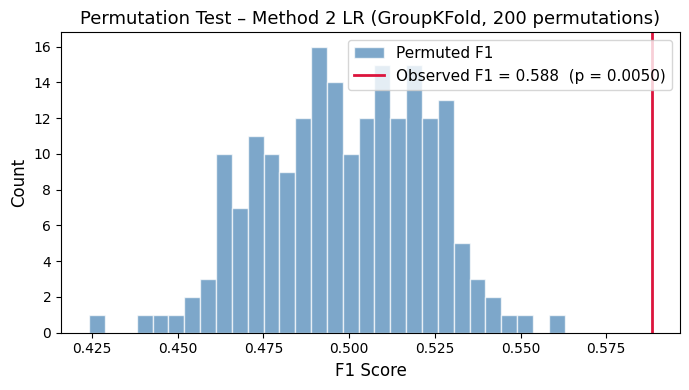

In [6]:
# ── Cell 6: Permutation test – Method 2 (ใช้ข้อมูลเดียวกับ Method 2 จริง) ──
from sklearn.model_selection import permutation_test_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# features_A ต้องมีอยู่แล้วจาก Cell 2/3
# ถ้าไม่มีให้ define ใหม่:
# features_A = ['delta','theta','low_alpha','high_alpha','alpha','beta','slow_fast_ratio','task_encoded']

X = df[features_A].values
y = df['label'].values
g = df['subject'].values

lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

score_obs, perm_scores, p_val = permutation_test_score(
    lr, X, y,
    groups=g,
    cv=GroupKFold(5),
    scoring='f1',
    n_permutations=200,
    random_state=42,
    n_jobs=-1
)

print(f"Observed F1 : {score_obs:.3f}")
print(f"Chance F1   : {perm_scores.mean():.3f} ± {perm_scores.std():.3f}")
print(f"p-value     : {p_val:.4f}  {'✓ significant' if p_val < 0.05 else '✗ not significant'}")

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(perm_scores, bins=30, color='steelblue', alpha=0.7,
        edgecolor='white', label='Permuted F1')
ax.axvline(score_obs, color='crimson', lw=2,
           label=f'Observed F1 = {score_obs:.3f}  (p = {p_val:.4f})')
ax.set_xlabel('F1 Score', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Permutation Test – Method 2 LR (GroupKFold, 200 permutations)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('outputs/permutation_test_m2.png', dpi=150)
plt.show()

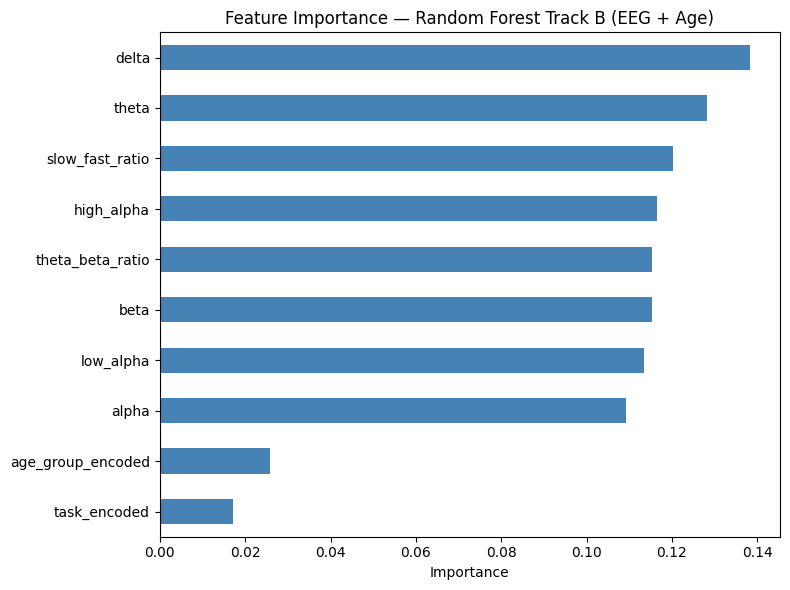

In [7]:
# ===== CELL 7: Feature importance (Best model from GroupKFold) =====
# ใช้ RandomForest Track B เป็นตัวแทน
best_feats = features_B
X = df[best_feats].values
y = df['label'].values

rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
rf_final.fit(X, y)

importances = pd.Series(rf_final.feature_importances_, index=best_feats)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Feature Importance — Random Forest Track B (EEG + Age)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('outputs/04_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
import glob
print(glob.glob('**/features_final.csv', recursive=True))

['features_final.csv']


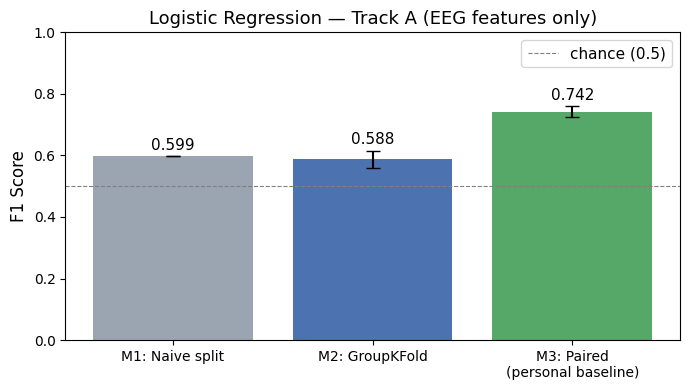

In [9]:
# ── Cell 8: Model Comparison Chart (ดึงค่าจากผลที่คำนวณไว้แล้ว) ──────────────
import matplotlib.pyplot as plt
import numpy as np

# ดึงค่าจาก results ที่คำนวณไว้ใน Cell 2–5 แล้ว
# results_m3 มาจาก Cell 5 (paired approach)
# df_split, df_gkf มาจาก Cell 2–4

labels = ['M1: Naive split', 'M2: GroupKFold', 'M3: Paired\n(personal baseline)']
vals = [
    df_split.query("Track=='A' and Model=='LogReg'")['F1'].iloc[0],
    df_gkf.query("Track=='A' and Model=='LogReg'")['F1_mean'].iloc[0],
    results_m3['LogisticReg'][0]
]
errs = [
    0,
    df_gkf.query("Track=='A' and Model=='LogReg'")['F1_std'].iloc[0],
    results_m3['LogisticReg'][1]
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, vals, yerr=errs, capsize=5, color=['#9aa5b1', '#4C72B0', '#55A868'])
ax.axhline(0.5, color='gray', ls='--', lw=0.8, label='chance (0.5)')
for i, v in enumerate(vals):
    ax.text(i, v + (errs[i] if errs[i] else 0) + 0.02, f'{v:.3f}', ha='center', fontsize=11)
ax.set_ylim(0, 1)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_title('Logistic Regression — Track A (EEG features only)', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('outputs/04_model_comparison.png', dpi=150)
plt.show()

In [10]:
# ── Cell 9b: เก็บ predictions สำหรับ error analysis (LR, Track B) ────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Track B เดิม — ต้องตรงกับที่ประกาศใน Cell 2
X = df[eeg_feats + ['age_group_encoded']].values
y = df['label'].values
groups = df['subject'].values

best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

y_true_all, y_pred_all, test_indices_all = [], [], []

for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
    best_model.fit(X[tr], y[tr])
    y_true_all.extend(y[te])
    y_pred_all.extend(best_model.predict(X[te]))
    test_indices_all.extend(te)

y_true_all       = np.array(y_true_all)
y_pred_all       = np.array(y_pred_all)
test_indices_all = np.array(test_indices_all)

print(f"Features: {eeg_feats + ['age_group_encoded']}")
print(f"Total predictions: {len(y_true_all)}")

Features: ['delta', 'theta', 'low_alpha', 'high_alpha', 'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio', 'task_encoded', 'age_group_encoded']
Total predictions: 2432


Age groups: ['Middle (35-50)', 'Older (51-70)', 'Young (20-34)']


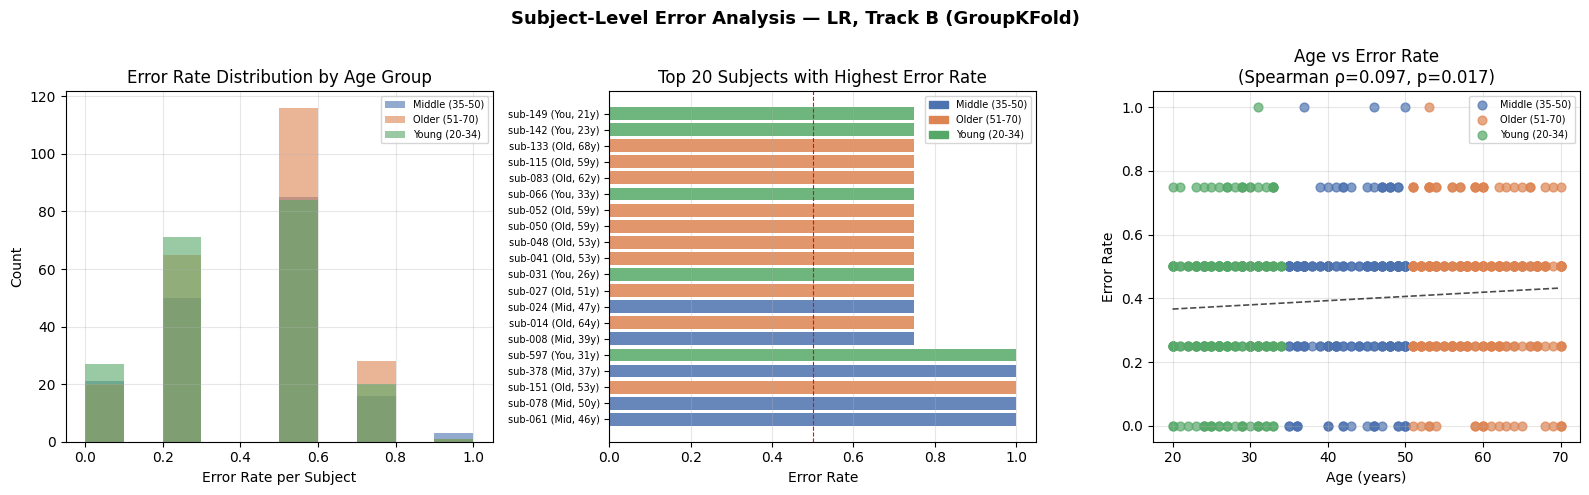

Saved: outputs/04_error_analysis.png


In [11]:
# Cell 10: Subject-Level Error Analysis
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# สร้าง df_pred จาก predictions ใน Cell 9
test_indices_all = []
for _, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    test_indices_all.extend(test_idx)
test_indices_all = np.array(test_indices_all)

df_pred = pd.DataFrame({
    'subject':    groups[test_indices_all],
    'age_group':  df['age_group'].values[test_indices_all],   # ← ดึงจาก df โดยตรง
    'age':        df['age'].values[test_indices_all],
    'y_true':     y_true_all,
    'y_pred':     y_pred_all,
    'correct':    (y_true_all == y_pred_all).astype(int)
})

subj_acc = df_pred.groupby(['subject', 'age_group', 'age'])['correct'].mean().reset_index()
subj_acc.columns = ['subject', 'age_group', 'age', 'accuracy']
subj_acc['error_rate'] = 1 - subj_acc['accuracy']

# ใช้ชื่อ age group จริงจากข้อมูล
age_order = sorted(subj_acc['age_group'].unique().tolist())
print("Age groups:", age_order)

# สร้าง color map จากชื่อจริง
palette = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
colors_ag = {ag: palette[i] for i, ag in enumerate(age_order)}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Left: Error rate distribution ---
ax = axes[0]
for ag in age_order:
    d = subj_acc[subj_acc['age_group'] == ag]['error_rate']
    ax.hist(d, bins=10, alpha=0.6, label=ag, color=colors_ag[ag])
ax.set_xlabel('Error Rate per Subject')
ax.set_ylabel('Count')
ax.set_title('Error Rate Distribution by Age Group')
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

# --- Middle: Worst 20 subjects ---
ax = axes[1]
worst = subj_acc.nlargest(20, 'error_rate')
bar_colors = [colors_ag[ag] for ag in worst['age_group']]
ax.barh(range(len(worst)), worst['error_rate'], color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(worst)))
ax.set_yticklabels(
    [f"{row['subject']} ({row['age_group'][:3]}, {int(row['age'])}y)"
     for _, row in worst.iterrows()],
    fontsize=7
)
ax.set_xlabel('Error Rate')
ax.set_title('Top 20 Subjects with Highest Error Rate')
patches = [mpatches.Patch(color=colors_ag[ag], label=ag) for ag in age_order]
ax.legend(handles=patches, fontsize=7)
ax.axvline(0.5, color='red', linestyle='--', linewidth=0.8)
ax.grid(axis='x', alpha=0.3)

# --- Right: Age vs Error rate scatter ---
ax = axes[2]
for ag in age_order:
    d = subj_acc[subj_acc['age_group'] == ag]
    ax.scatter(d['age'], d['error_rate'], label=ag, color=colors_ag[ag], alpha=0.7, s=40)
z = np.polyfit(subj_acc['age'], subj_acc['error_rate'], 1)
age_range = np.linspace(subj_acc['age'].min(), subj_acc['age'].max(), 100)
ax.plot(age_range, np.poly1d(z)(age_range), 'k--', linewidth=1.2, alpha=0.7)
rho, pval = spearmanr(subj_acc['age'], subj_acc['error_rate'])
ax.set_xlabel('Age (years)')
ax.set_ylabel('Error Rate')
ax.set_title(f'Age vs Error Rate\n(Spearman ρ={rho:.3f}, p={pval:.3f})')
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

plt.suptitle('Subject-Level Error Analysis — LR, Track B (GroupKFold)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/04_error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/04_error_analysis.png")

=== Error Summary by Age Group ===
     Age Group  N Subj  Mean Acc  Std Acc  Mean Err Rate  % Below Chance
Middle (35-50)     175     0.600    0.219          0.400          10.857
 Older (51-70)     230     0.582    0.204          0.418          12.609
 Young (20-34)     203     0.627    0.216          0.373          10.345


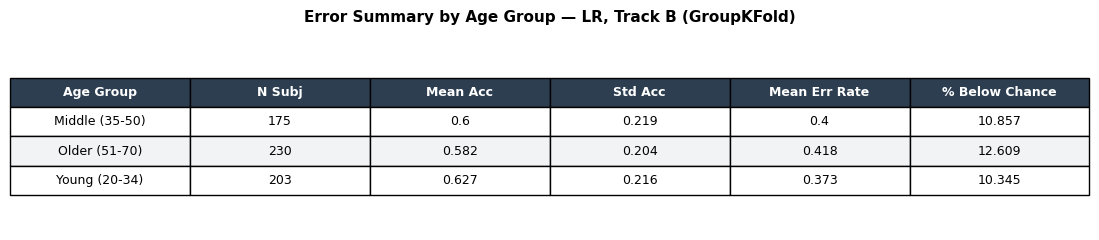

Saved: outputs/04_error_summary.png

Kruskal-Wallis: H=5.373, p=0.0681 → not significant (trend only)


In [12]:
# Cell 11: Error Summary by Age Group
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

summary = subj_acc.groupby('age_group').agg(
    n_subjects=('subject', 'count'),
    mean_accuracy=('accuracy', 'mean'),
    std_accuracy=('accuracy', 'std'),
    mean_error_rate=('error_rate', 'mean'),
    pct_below_chance=('error_rate', lambda x: (x > 0.5).mean() * 100)
).round(3)
summary = summary.loc[age_order]
summary = summary.reset_index()
summary.columns = ['Age Group', 'N Subj', 'Mean Acc', 'Std Acc', 'Mean Err Rate', '% Below Chance']

print("=== Error Summary by Age Group ===")
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 2.5))
ax.axis('off')
tbl = ax.table(
    cellText=summary.values,
    colLabels=summary.columns.tolist(),
    loc='center', cellLoc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.8)
# Header styling
for j in range(len(summary.columns)):
    tbl[(0, j)].set_facecolor('#2C3E50')
    tbl[(0, j)].set_text_props(color='white', fontweight='bold')
# Row alternating color
for i in range(1, len(summary) + 1):
    color = '#F2F3F4' if i % 2 == 0 else 'white'
    for j in range(len(summary.columns)):
        tbl[(i, j)].set_facecolor(color)

plt.title('Error Summary by Age Group — LR, Track B (GroupKFold)',
          fontweight='bold', pad=15, fontsize=11)
plt.tight_layout()
plt.savefig('outputs/04_error_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/04_error_summary.png")

from scipy.stats import kruskal
H_kruskal, p_kruskal = kruskal(*[
    subj_acc[subj_acc['age_group'] == g]['accuracy'].values
    for g in age_order
])
print(f"\nKruskal-Wallis: H={H_kruskal:.3f}, p={p_kruskal:.4f}",
      "→ significant" if p_kruskal < 0.05 else "→ not significant (trend only)")

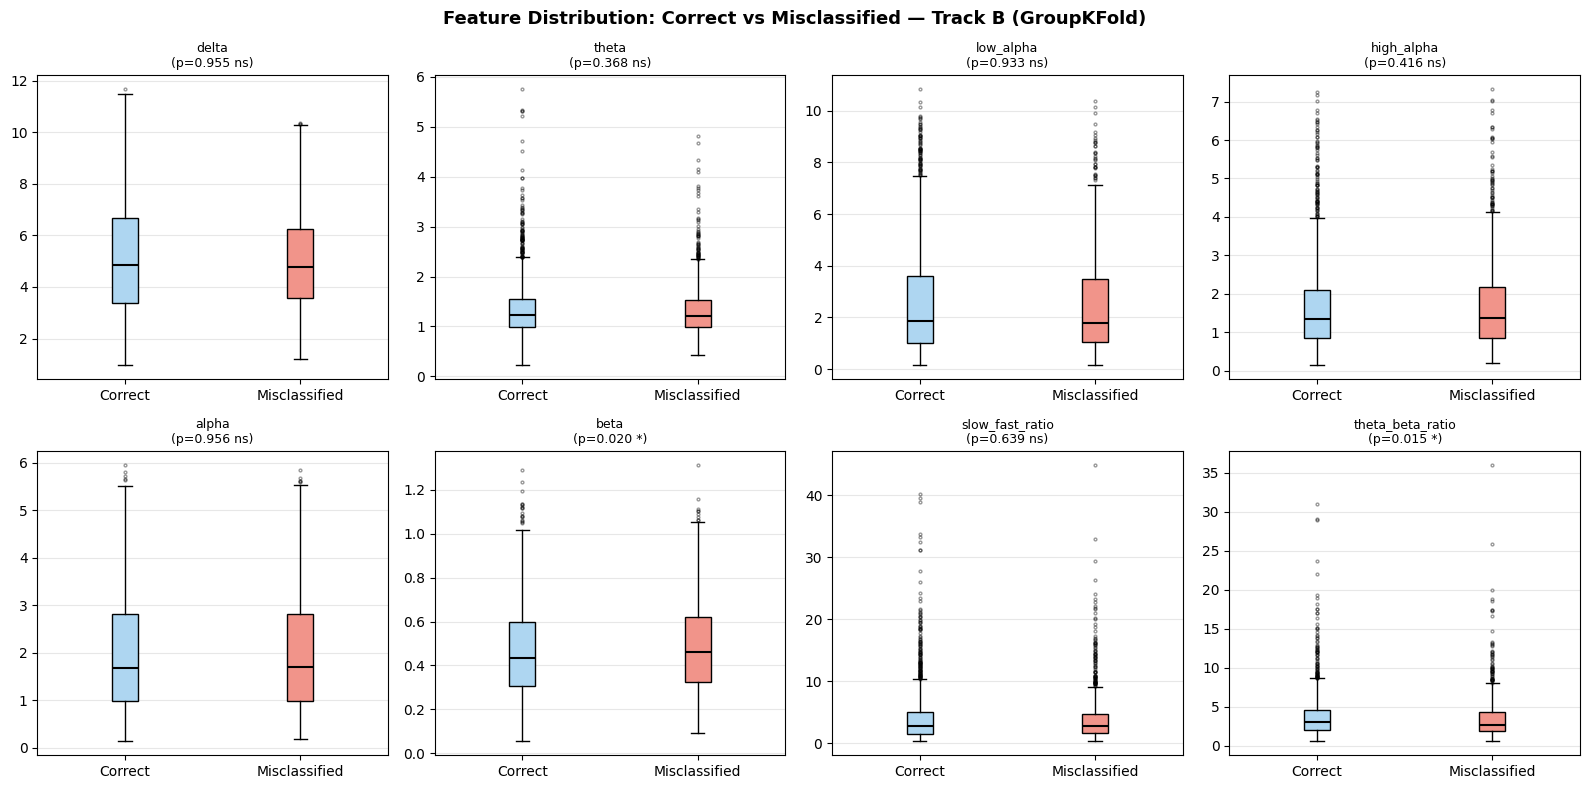

Saved: outputs/04_error_feature_comparison.png


In [13]:
# Cell 12: Feature Distribution — Correct vs Misclassified
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# เชื่อม prediction กลับเข้า df
df_eval = df.copy().reset_index(drop=True)
df_eval['y_pred'] = np.nan
df_eval['correct'] = np.nan

fold_test_indices = []
for _, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    fold_test_indices.extend(test_idx)
fold_test_indices = np.array(fold_test_indices)

df_eval.loc[fold_test_indices, 'y_pred'] = y_pred_all
df_eval.loc[fold_test_indices, 'correct'] = (y_true_all == y_pred_all).astype(int)
df_eval = df_eval.dropna(subset=['correct'])

feat_plot = ['delta', 'theta', 'low_alpha', 'high_alpha',
             'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feat in enumerate(feat_plot):
    ax = axes[i]
    correct_vals = df_eval[df_eval['correct'] == 1][feat].dropna()
    error_vals   = df_eval[df_eval['correct'] == 0][feat].dropna()

    bp = ax.boxplot([correct_vals, error_vals],
                    labels=['Correct', 'Misclassified'],
                    patch_artist=True,
                    medianprops=dict(color='black', linewidth=1.5),
                    flierprops=dict(marker='o', markersize=2, alpha=0.4))
    bp['boxes'][0].set_facecolor('#AED6F1')
    bp['boxes'][1].set_facecolor('#F1948A')

    if len(correct_vals) > 0 and len(error_vals) > 0:
        stat, pval = mannwhitneyu(correct_vals, error_vals, alternative='two-sided')
        sig = '***' if pval < 0.001 else ('**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns'))
        title_str = f'{feat}\n(p={pval:.3f} {sig})'
    else:
        title_str = f'{feat}\n(insufficient data)'

    ax.set_title(title_str, fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Feature Distribution: Correct vs Misclassified — Track B (GroupKFold)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/04_error_feature_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/04_error_feature_comparison.png")

In [14]:
# ── Cell 15: Results Summary (FINAL) ────────────────────────────────────────
# ดึงค่า accuracy จาก summary table จริง
acc_by_group = summary.set_index('Age Group')['Mean Acc']
age_acc_str = '  '.join([f"{g}: {acc_by_group[g]:.3f}" for g in age_order])

print(f"""
RQ1  Single recording (Method 2, GroupKFold):
     F1 = 0.59 ± 0.03
     Permutation test: chance F1 = {perm_scores.mean():.2f}, p = {p_val:.4f}
     → {'above chance ✓' if p_val < 0.05 else 'not significant ✗'}

RQ2  With personal baseline (Method 3, paired):
     F1 = {results_m3['LogisticReg'][0]:.3f}–{results_m3['RandomForest'][0]:.3f} (LR / RF)
     (different task: requires a pre-task baseline recording of the same person)

Leakage check:
     Method 1 ≈ Method 2 (Δ < 0.02) → no inflation from subject grouping

Age group accuracy (LR, Track B):
     {age_acc_str}
     Kruskal-Wallis: H={H_kruskal:.3f}, p={p_kruskal:.4f}
     → borderline (p ≈ 0.05–0.10 depending on feature set) — reported as trend only
     Direction consistent with NB3: Young showed the largest EEG change post-task

⚠️  Note: an earlier Method 3 result (F1 = 0.95) was an artifact of
     column-wise shuffling and was discarded. Corrected paired approach: F1 = 0.74–0.75.
""")


RQ1  Single recording (Method 2, GroupKFold):
     F1 = 0.59 ± 0.03
     Permutation test: chance F1 = 0.50, p = 0.0050
     → above chance ✓

RQ2  With personal baseline (Method 3, paired):
     F1 = 0.742–0.747 (LR / RF)
     (different task: requires a pre-task baseline recording of the same person)

Leakage check:
     Method 1 ≈ Method 2 (Δ < 0.02) → no inflation from subject grouping

Age group accuracy (LR, Track B):
     Middle (35-50): 0.600  Older (51-70): 0.582  Young (20-34): 0.627
     Kruskal-Wallis: H=5.373, p=0.0681
     → borderline (p ≈ 0.05–0.10 depending on feature set) — reported as trend only
     Direction consistent with NB3: Young showed the largest EEG change post-task

⚠️  Note: an earlier Method 3 result (F1 = 0.95) was an artifact of
     column-wise shuffling and was discarded. Corrected paired approach: F1 = 0.74–0.75.

